# 02 — Preprocessing the NSL-KDD dataset
**MSc AI dissertation · Ghanem Almarar · Phase 2**

This notebook *narrates* the fixed preprocessing pipeline. The real implementation lives in
[`src/preprocessing.py`](../src/preprocessing.py); every cell below imports from it so the notebook and the
script can never disagree. Re-running `python -m src.preprocessing` regenerates every artefact.

**Why a fixed pipeline matters.** The whole research design rests on one idea: if Random Forest, SVM and
Decision Tree all see *exactly* the same inputs, then any difference in their results is caused by the
algorithm — not by preprocessing choices. So this pipeline is run once, saved to disk, and every model loads
the same files.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import preprocessing as pp
pd.set_option("display.max_columns", 60)
print("project root:", ROOT)

project root: C:\Users\PC\Desktop\MSc-IDS-Comparative-Study


## Step 1 — Load the raw files with the 43 official column names
The `.txt` files have **no header row**. We attach the 41 feature names from Tavallaee et al. (2009),
plus `label` and `difficulty`. Row counts must be 125,973 (train) and 22,544 (test) — the figures quoted in
the research proposal.

In [2]:
train_raw = pp.load_raw("KDDTrain+.txt")
test_raw  = pp.load_raw("KDDTest+.txt")
train_raw.head()

[load] KDDTrain+.txt: 125,973 rows x 43 cols


[load] KDDTest+.txt: 22,544 rows x 43 cols


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## Step 2 — Drop `difficulty`
`difficulty` is a per-record score added by the NSL-KDD authors describing how many of 21 learners
mis-classified that record. It is *metadata about the benchmark*, not a property of the network traffic —
keeping it would leak information about the label. Out it goes.

In [3]:
train_df = pp.drop_difficulty(train_raw)
test_df  = pp.drop_difficulty(test_raw)
print(train_df.shape, test_df.shape)

(125973, 42) (22544, 42)


## Step 3 — Map 39 raw attack names → 5 classes
NSL-KDD labels each connection with a specific attack (`neptune`, `smurf`, `rootkit` …). Following the
standard taxonomy we collapse these into **Normal, DoS, Probe, R2L, U2R**. Note the severe imbalance:
U2R has only **52** training rows out of 125,973 (0.04 %). Also note that KDDTest+ contains attack
*types* never seen in training (e.g. `apache2`, `mscan`, `snmpguess`) — the mapping covers them so the
official test set can be evaluated; this is the "unseen attacks" property that feeds **RQ3**.

In [4]:
train_df = pp.map_labels(train_df)
test_df  = pp.map_labels(test_df)
dist = pd.DataFrame({
    "KDDTrain+": train_df["attack_class"].value_counts(),
    "KDDTest+":  test_df["attack_class"].value_counts(),
}).reindex(pp.CLASS_ORDER)
dist["train %"] = (dist["KDDTrain+"] / dist["KDDTrain+"].sum() * 100).round(2)
dist["test %"]  = (dist["KDDTest+"]  / dist["KDDTest+"].sum()  * 100).round(2)
dist

,KDDTrain+,KDDTest+,train %,test %
attack_class,,,,
Normal,67343,9711,53.46,43.08
DoS,45927,7460,36.46,33.09
Probe,11656,2421,9.25,10.74
R2L,995,2885,0.79,12.80
U2R,52,67,0.04,0.30


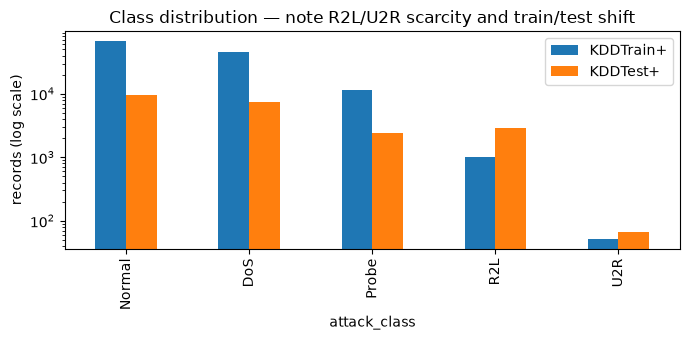

In [5]:
fig, ax = plt.subplots(figsize=(7,3.5))
dist[["KDDTrain+","KDDTest+"]].plot(kind="bar", ax=ax, logy=True)
ax.set_ylabel("records (log scale)"); ax.set_title("Class distribution — note R2L/U2R scarcity and train/test shift")
plt.tight_layout(); plt.show()

## Steps 4–5 — One-hot encode the 3 nominal features, then align columns
`protocol_type` (3 values), `service` (~70) and `flag` (11) are categories with no numeric order, so we
one-hot encode them. Because KDDTest+ contains `service` values absent from training (and vice-versa),
the two frames end up with different columns; `align_columns` gives both the same 122 feature columns,
filling missing ones with 0.

In [6]:
train_df, test_df = pp.align_columns(pp.one_hot(train_df), pp.one_hot(test_df))
print("feature columns after encoding:", train_df.shape[1]-1)
assert list(train_df.columns) == list(test_df.columns)

feature columns after encoding: 122


## Steps 6–7 — Encode the target and make a stratified 80/20 split of KDDTrain+
*Stratified* means every class keeps the same proportion on both sides — essential when U2R has 52 rows.
`random_state=42` everywhere so the split is reproducible.

> **Design decision D2.** The 80 % part is used for 10-fold cross-validation and training; the 20 % holdout
> is an in-distribution test; **KDDTest+** is kept as a second, *official* out-of-distribution test.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
X_all, y_all = pp.split_xy(train_df)
X_off, y_off_raw = pp.split_xy(test_df)
le = LabelEncoder().fit(pp.CLASS_ORDER)
y_all_enc, y_off = le.transform(y_all), le.transform(y_off_raw)
print("class → integer:", dict(zip(le.classes_, le.transform(le.classes_))))
X_tr, X_ho, y_tr, y_ho = train_test_split(X_all, y_all_enc, test_size=pp.TEST_SIZE,
                                          stratify=y_all_enc, random_state=pp.RANDOM_STATE)
print(f"train {len(X_tr):,} | holdout {len(X_ho):,} | official test {len(X_off):,}")

class → integer: {np.str_('DoS'): np.int64(0), np.str_('Normal'): np.int64(1), np.str_('Probe'): np.int64(2), np.str_('R2L'): np.int64(3), np.str_('U2R'): np.int64(4)}
train 100,778 | holdout 25,195 | official test 22,544


## Step 8 — Min-Max scaling, fitted on the 80 % train **only**
Features range from 0/1 flags to `src_bytes` in the millions. SVM in particular is distance-based and would be
dominated by large-magnitude columns. We scale everything to [0, 1]. The scaler learns its min/max from the
training part only — fitting it on test data would be **data leakage**.

In [8]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler().fit(X_tr)
cols = list(X_tr.columns)
X_tr_s = pd.DataFrame(scaler.transform(X_tr), columns=cols)
X_ho_s = pd.DataFrame(scaler.transform(X_ho), columns=cols)
X_off_s = pd.DataFrame(scaler.transform(X_off), columns=cols)
X_tr_s.describe().loc[["min","max"]].T.describe()   # sanity: all mins 0, all maxes ≤ 1

,min,max
count,122.0,122.000000
mean,0.0,0.991803
std,0.0,0.090536
min,0.0,0.000000
25%,0.0,1.000000
50%,0.0,1.000000
75%,0.0,1.000000
max,0.0,1.000000


## Step 9 — SMOTE on the 80 % train **only**
SMOTE (Chawla et al., 2002) creates *synthetic* minority-class rows by interpolating between real neighbours,
until every class has as many rows as the majority class. It is applied **only** to the training part:
evaluating on synthetic rows would be meaningless, and the test sets must stay a faithful picture of reality.
Result: 5 × 53,874 = 269,370 balanced training rows.

In [9]:
from imblearn.over_sampling import SMOTE
before = pd.Series(le.inverse_transform(y_tr)).value_counts().reindex(pp.CLASS_ORDER)
X_tr_bal, y_tr_bal = SMOTE(random_state=pp.RANDOM_STATE).fit_resample(X_tr_s, y_tr)
after = pd.Series(le.inverse_transform(y_tr_bal)).value_counts().reindex(pp.CLASS_ORDER)
pd.DataFrame({"before SMOTE": before, "after SMOTE": after})

,before SMOTE,after SMOTE
Normal,53874,53874
DoS,36741,53874
Probe,9325,53874
R2L,796,53874
U2R,42,53874


## Step 10 — Random-Forest feature importance → keep the top 20
A 100-tree Random Forest is fitted on the balanced training set and its Gini importance ranks all 122
columns. We keep the 20 most informative (as promised in the proposal) — fewer dimensions, faster SVM, and
the same 20 columns are used by all three classifiers.

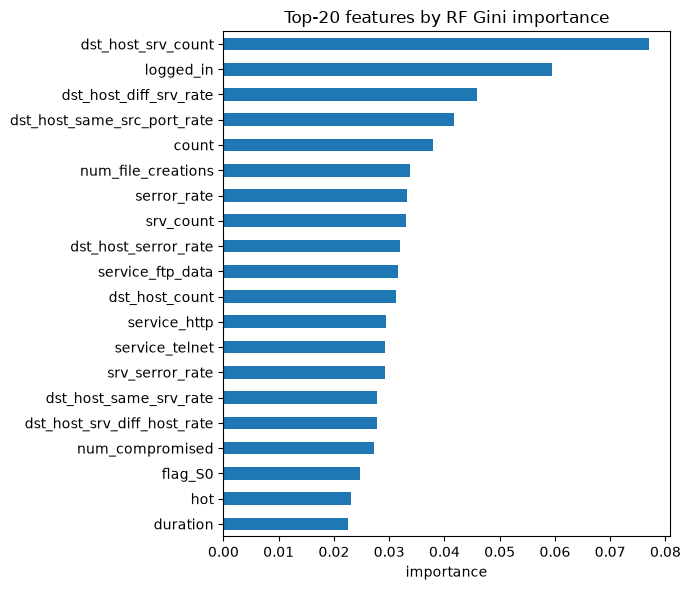

dst_host_srv_count             0.076946
logged_in                      0.059448
dst_host_diff_srv_rate         0.045926
dst_host_same_src_port_rate    0.041668
count                          0.037995
num_file_creations             0.033811
serror_rate                    0.033254
srv_count                      0.032991
dst_host_serror_rate           0.031887
service_ftp_data               0.031563
dst_host_count                 0.031250
service_http                   0.029438
service_telnet                 0.029286
srv_serror_rate                0.029241
dst_host_same_srv_rate         0.027787
dst_host_srv_diff_host_rate    0.027739
num_compromised                0.027239
flag_S0                        0.024801
hot                            0.023157
duration                       0.022599
dtype: float64

In [10]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=pp.RANDOM_STATE, n_jobs=-1).fit(X_tr_bal, y_tr_bal)
imp = pd.Series(rf.feature_importances_, index=cols).sort_values(ascending=False)
top20 = imp.head(pp.TOP_K_FEATURES)
fig, ax = plt.subplots(figsize=(7,6))
top20[::-1].plot(kind="barh", ax=ax); ax.set_title("Top-20 features by RF Gini importance"); ax.set_xlabel("importance")
plt.tight_layout()
(ROOT/"results"/"figures").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT/"results"/"figures"/"fig_rf_top20_importance.png", dpi=200, bbox_inches="tight"); plt.show()
top20

## Step 11 — Persist everything (run the script, not the cells, for the canonical artefacts)
The cell below runs the full pipeline from `src/preprocessing.py` and writes:
* `data/processed/nslkdd_processed.npz` — X/y for train (SMOTE'd, top-20), holdout, official test
* `models/minmax_scaler.pkl`, `models/label_encoder.pkl`, `models/top20_features.pkl`
* `results/tables/rf_feature_importance_*.csv`, `data/processed/class_distribution.json`, `pipeline_meta.json`

In [11]:
out = pp.run()
meta = json.loads((ROOT/"data"/"processed"/"pipeline_meta.json").read_text())
meta["shapes"], meta["class_encoding"]

[load] KDDTrain+.txt: 125,973 rows x 43 cols
[load] KDDTest+.txt: 22,544 rows x 43 cols

[KDDTrain+ class counts]
attack_class
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52

[KDDTest+ class counts]
attack_class
Normal    9711
DoS       7460
Probe     2421
R2L       2885
U2R         67

[one-hot] feature columns after encoding: 122
[label-encode] classes -> {np.str_('DoS'): np.int64(0), np.str_('Normal'): np.int64(1), np.str_('Probe'): np.int64(2), np.str_('R2L'): np.int64(3), np.str_('U2R'): np.int64(4)}


[split] train 100,778 | holdout 25,195 | official test 22,544

[Train (80 %) BEFORE SMOTE]
Normal    53874
DoS       36741
Probe      9325
R2L         796
U2R          42



[Train (80 %) AFTER SMOTE]
Normal    53874
DoS       53874
Probe     53874
R2L       53874
U2R       53874



[feature-selection] top 20 features:
dst_host_srv_count             0.076946
logged_in                      0.059448
dst_host_diff_srv_rate         0.045926
dst_host_same_src_port_rate    0.041668
count                          0.037995
num_file_creations             0.033811
serror_rate                    0.033254
srv_count                      0.032991
dst_host_serror_rate           0.031887
service_ftp_data               0.031563
dst_host_count                 0.031250
service_http                   0.029438
service_telnet                 0.029286
srv_serror_rate                0.029241
dst_host_same_srv_rate         0.027787
dst_host_srv_diff_host_rate    0.027739
num_compromised                0.027239
flag_S0                        0.024801
hot                            0.023157
duration                       0.022599



[done] saved to C:\Users\PC\Desktop\MSc-IDS-Comparative-Study\data\processed and C:\Users\PC\Desktop\MSc-IDS-Comparative-Study\models in 5.7s


({'X_train': [269370, 20],
  'X_holdout': [25195, 20],
  'X_test_official': [22544, 20]},
 {'DoS': 0, 'Normal': 1, 'Probe': 2, 'R2L': 3, 'U2R': 4})

## What to carry into the dissertation
* **Ch3 Methodology** — the 11 steps above, in this order, with the leakage-prevention reasoning (scaler & SMOTE fit on train only) and decision D2.
* **Ch4 Results** — Table: class distribution (train / test / before / after SMOTE); Figure: top-20 importance.
* **Ch5 / Ethics** — U2R = 52 rows; KDDTest+ has ~3× the R2L share of training → distribution shift to discuss under RQ3 and fairness.